# Lab 2 - Od perceptronu do MLP (NumPy, Keras i PyTorch)


**Kurs:** Uczenie głębokie (Informatyka, II stopień, sem. III, studia niestacjonarne, 2025/2026)
**Prowadząca:** dr inż. Natalia Piórkowska
**Czas:** 180 min (Google Colab, GPU T4)
**Treści programowe:** T2 (komponenty: warstwy gęste, komponenty nieliniowe; biblioteki Keras i PyTorch), T3 (perceptron, MLP, klasyczne sieci do klasyfikacji)

## Cel zajęć
Przejdziemy drogę, którą przeszła cała dziedzina: od **perceptronu Rosenblatta** (1958) przez jego słynną porażkę na problemie **XOR**, aż do **wielowarstwowej sieci (MLP)** trenowanej **propagacją wsteczną** (1986). Najpierw wszystko napiszesz od zera w NumPy - żeby zrozumieć każdy wzór - a potem zbudujesz te same modele w **Keras** (Sequential i Functional API) oraz w **PyTorch** (`nn.Module`, pętla treningowa, `DataLoader`). Na koniec zobaczysz, jak liczba warstw i neuronów zmienia granicę decyzyjną.

## Efekty uczenia (z karty przedmiotu)
- **UGŁ_W01** - zna klasyczne modele (perceptron), metody uczenia sieci (reguła perceptronu, backpropagation) i modele DL (MLP).
- **UGŁ_W02** - zna narzędzia: Keras (Sequential/Functional), PyTorch (`nn.Module`, `DataLoader`).
- **UGŁ_U01** - formułuje i weryfikuje hipotezy (np. "perceptron nie rozwiąże XOR", "sigmoid w głębokiej sieci powoduje znikanie gradientu").
- **UGŁ_U02** - wykorzystuje istniejące biblioteki do budowy i usprawniania modeli.

## Powiązanie z wykładem
- **W2** - neuron, warstwa gęsta ($W\mathbf x + \mathbf b$, liczba parametrów), funkcje aktywacji i znikający gradient, graf obliczeniowy i backpropagation, ekosystem Keras/PyTorch.
- **W3** - perceptron Rosenblatta i reguła uczenia, XOR i ograniczenia, MLP i twierdzenie o uniwersalnej aproksymacji, funkcje straty (BCE), inicjalizacja wag, Keras: Sequential/Functional, PyTorch: `nn.Module`, pętla treningowa.

## Harmonogram (180 min)
| Czas | Część |
|---|---|
| 0-10 min | Przypomnienie L1, uruchomienie środowiska (sekcja 0) |
| 10-35 min | 1. Perceptron Rosenblatta od zera, porażka na XOR (Zadania 1.1-1.2) |
| 35-55 min | 2. Funkcje aktywacji i znikający gradient (Zadania 2.1-2.2) |
| 55-90 min | 3. MLP od zera z ręcznym backpropem - XOR (Zadania 3.1-3.2) |
| 90-100 min | **Przerwa** |
| 100-130 min | 4. MLP w Keras: Sequential i Functional API (Zadania 4.1-4.2) |
| 130-155 min | 5. Ten sam model w PyTorch (Zadanie 5.1) |
| 155-175 min | 6. Pojemność: liczba warstw i neuronów a granica decyzyjna (Zadanie 6.1) |
| 175-180 min | Pytania kontrolne, podsumowanie |

## Wymagania wstępne
- Lab 1: tensory w TF/PyTorch, autograd, spadek gradientu, gradient check, train vs walidacja.
- Mnożenie macierzy, reguła łańcuchowa, pochodne funkcji $e^x$, $\tanh x$.

> **Jak pracować z notebookiem?** Uruchamiaj komórki po kolei (Shift+Enter). Komórki z `# TODO` uzupełniasz samodzielnie - polecenie i kryteria sukcesu są w komórce markdown tuż nad nimi.

## 0. Przygotowanie środowiska

### 0.1 Włączenie GPU w Google Colab
1. Menu **Środowisko wykonawcze -> Zmień typ środowiska wykonawczego**.
2. *Akcelerator sprzętowy*: **T4 GPU** -> *Zapisz*.
3. Uruchom komórki poniżej. Dzisiejsze modele są małe - na CPU też zadziałają (wtedy ustaw `SZYBKI_TRYB = True`, jeśli trening trwa zbyt długo).

Uwaga: dla bardzo małych sieci i zbiorów (jak dziś) GPU **nie musi** być szybsze od CPU - narzut na przesyłanie danych i uruchamianie jąder CUDA dominuje nad obliczeniami. GPU wygrywa przy dużych modelach i batchach (L4).

In [106]:
!nvidia-smi

Mon Oct 19 16:39:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   64C    P0             29W /   70W |     265MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 0.2 Importy, tryb szybki, seedy
`SZYBKI_TRYB = True` (lub zmienna środowiskowa `DL_FAST=1`) zmniejsza liczbę epok i próbek - używaj, gdy pracujesz bez GPU. Wnioski jakościowe są te same, ale granice decyzyjne będą mniej dopracowane.

Jak na L1 włączamy w TF `memory_growth`, żeby TensorFlow (pod Keras) nie zajął całej pamięci GPU, której potrzebuje też PyTorch.

In [107]:
import os, time, math
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf

import tensorflow as tf
for _gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(_gpu, True)   # TF bierze pamięć GPU stopniowo
import keras
from keras import layers

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import make_blobs, make_moons, make_circles
from sklearn.model_selection import train_test_split

# Tryb szybki: True = mniej danych i epok (praca bez GPU)

SZYBKI_TRYB = False   # <- odkomentuj, jeśli pracujesz bez GPU

SEED = 42
keras.utils.set_random_seed(SEED)      # Python + NumPy + TF
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("SZYBKI_TRYB =", SZYBKI_TRYB)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| backend:", keras.backend.backend())
print("PyTorch", torch.__version__, "| DEVICE =", DEVICE)
print("GPU (TF):", tf.config.list_physical_devices("GPU"))

SZYBKI_TRYB = False
TensorFlow 2.21.0 | Keras 3.13.2 | backend: tensorflow
PyTorch 2.11.0+cu130 | DEVICE = cuda
GPU (TF): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 0.3 Funkcja pomocnicza: rysowanie granicy decyzyjnej
Dla danych 2D najlepszym sposobem zrozumienia klasyfikatora jest narysowanie jego **granicy decyzyjnej**: liczymy predykcję modelu w każdym punkcie gęstej siatki i kolorujemy płaszczyznę. Funkcja przyjmuje dowolną funkcję `predict_fn`, która dla tablicy punktów `(m, 2)` zwraca:
- prawdopodobieństwo klasy 1 (wartości z $[0, 1]$) - wtedy czarna linia to granica $p = 0.5$,
- albo etykiety klas (`wieloklasowa=True`).

Dzięki temu tę samą funkcję użyjemy dla perceptronu w NumPy, modelu Keras i modelu PyTorch.

In [108]:
def rysuj_granice(predict_fn, X, y, ax=None, tytul="", rozdz=200, wieloklasowa=False):
    '''Rysuje granicę decyzyjną klasyfikatora 2D i punkty danych.'''
    if ax is None:
        _, ax = plt.subplots(figsize=(5.5, 4.5))
    marg = 0.5
    x_min, x_max = X[:, 0].min() - marg, X[:, 0].max() + marg
    y_min, y_max = X[:, 1].min() - marg, X[:, 1].max() + marg
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, rozdz), np.linspace(y_min, y_max, rozdz))
    siatka = np.c_[xx.ravel(), yy.ravel()].astype(np.float32)   # (rozdz^2, 2) punktów
    Z = np.asarray(predict_fn(siatka), dtype=float).reshape(xx.shape)
    if wieloklasowa:
        k = int(max(Z.max(), y.max())) + 1
        ax.contourf(xx, yy, Z, levels=np.arange(k + 1) - 0.5, cmap="tab10", vmin=0, vmax=9, alpha=0.3)
        kolory = plt.cm.tab10(np.arange(k))
    else:
        ax.contourf(xx, yy, Z, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.45)
        if Z.min() < 0.5 < Z.max():                       # granica p = 0.5
            ax.contour(xx, yy, Z, levels=[0.5], colors="k", linewidths=1.5)
        kolory = ["tab:blue", "tab:red"]
    for kl in np.unique(y):                               # punkty każdej klasy osobno -> legenda
        m = y == kl
        ax.scatter(X[m, 0], X[m, 1], color=kolory[int(kl)], edgecolors="k", s=18, label=f"klasa {int(kl)}")
    ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)
    ax.set_title(tytul); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.legend(fontsize=8, loc="best")
    return ax

## 1. Perceptron Rosenblatta

### 1.1 Model
Perceptron (Frank Rosenblatt, 1958) to pierwszy uczący się model neuronu. Liczy ważoną sumę wejść i przepuszcza ją przez **funkcję progową** (skok Heaviside'a):
$$\hat y = \text{step}(\mathbf w^\top\mathbf x + b) = \begin{cases}1 & \text{gdy } \mathbf w^\top\mathbf x + b \ge 0\\ 0 & \text{w przeciwnym razie.}\end{cases}$$
Geometrycznie: równanie $\mathbf w^\top\mathbf x + b = 0$ to **hiperpłaszczyzna** (w 2D - prosta), a perceptron mówi, po której stronie leży punkt. $\mathbf w$ jest wektorem normalnym do prostej, $b$ ją przesuwa.

### 1.2 Reguła uczenia perceptronu
Przeglądamy próbki po kolei. Dla każdej próbki $(\mathbf x_i, y_i)$, $y_i \in \{0, 1\}$:
$$\mathbf w \leftarrow \mathbf w + \eta\,(y_i - \hat y_i)\,\mathbf x_i, \qquad b \leftarrow b + \eta\,(y_i - \hat y_i).$$
- Poprawna klasyfikacja: $y_i - \hat y_i = 0$ -> brak zmiany.
- Fałszywie negatywna ($y=1$, $\hat y=0$): dodajemy $\mathbf x_i$ do $\mathbf w$ - prosta "obraca się" w stronę punktu.
- Fałszywie pozytywna ($y=0$, $\hat y=1$): odejmujemy $\mathbf x_i$.

To **nie jest** spadek gradientu (funkcja skokowa ma pochodną 0 prawie wszędzie!) - to reguła heurystyczna. **Twierdzenie o zbieżności perceptronu** (Novikoff, 1962): jeśli dane są **liniowo separowalne** z marginesem $\gamma$ i $\|\mathbf x_i\| \le R$, to algorytm wykona co najwyżej $(R/\gamma)^2$ błędnych aktualizacji. Jeśli dane **nie** są liniowo separowalne - algorytm nigdy się nie zatrzyma.

X: (200, 2)  klasy: [100 100]


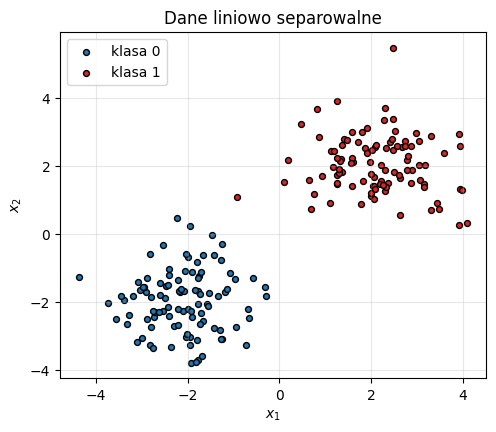

In [109]:
# Dane liniowo separowalne: dwie dobrze rozdzielone chmury punktów
X_lin, y_lin = make_blobs(n_samples=200, centers=[[-2, -2], [2, 2]], cluster_std=0.9, random_state=SEED)
print("X:", X_lin.shape, " klasy:", np.bincount(y_lin))

plt.figure(figsize=(5.5, 4.5))
for kl, kol in zip([0, 1], ["tab:blue", "tab:red"]):
    plt.scatter(X_lin[y_lin == kl, 0], X_lin[y_lin == kl, 1], color=kol, edgecolors="k", s=18, label=f"klasa {kl}")
plt.title("Dane liniowo separowalne"); plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.legend(); plt.grid(alpha=0.3); plt.show()

### Zadanie 1.1 - Perceptron od zera w NumPy
Uzupełnij klasę `PerceptronRosenblatta`:
1. `predict(X)` - zwraca wektor etykiet 0/1 dla wszystkich wierszy `X` (wektorowo, bez pętli).
2. `fit(X, y, epoki)` - w każdej epoce przejdź po próbkach (w losowej kolejności - permutacja jest gotowa), policz $\hat y_i$, zaktualizuj `self.w` i `self.b` regułą perceptronu i **zlicz błędy** w epoce (zmienna `bledy`). Kod zapisujący liczbę błędów i zatrzymujący trening przy 0 błędów jest gotowy.

**Kryteria sukcesu:** na danych `X_lin` perceptron osiąga 0 błędów po kilku epokach, dokładność = 100%.

**Wskazówka:** dla pojedynczej próbki `xi` (kształt `(2,)`) `self.net(xi)` jest skalarem.

In [110]:
class PerceptronRosenblatta:
    def __init__(self, n_wejsc, eta=0.1, seed=0):
        self.rng = np.random.default_rng(seed)
        self.w = self.rng.normal(scale=0.01, size=n_wejsc)   # małe losowe wagi
        self.b = 0.0
        self.eta = eta
        self.bledy = []                                      # liczba błędów w każdej epoce

    def net(self, X):
        # pobudzenie neuronu: w^T x + b
        return X @ self.w + self.b

    def predict(self, X):
        return (self.net(X) >= 0).astype(int)

    def fit(self, X, y, epoki=20):
        for ep in range(epoki):
            bledy = 0
            for i in self.rng.permutation(len(X)):           # losowa kolejność próbek
                xi, yi = X[i], y[i]
                y_hat = int(self.net(xi) >= 0)
                delta = int(yi) - y_hat
                self.w += self.eta * delta * xi
                self.b += self.eta * delta
                bledy += int(delta != 0)
            self.bledy.append(bledy)
            if bledy == 0:                                   # zbieżność - wszystkie poprawnie
                break
        return self

epok: 2, błędy w epokach: [1, 0]
dokładność: 1.000, w = [0.196 0.302], b = -0.100


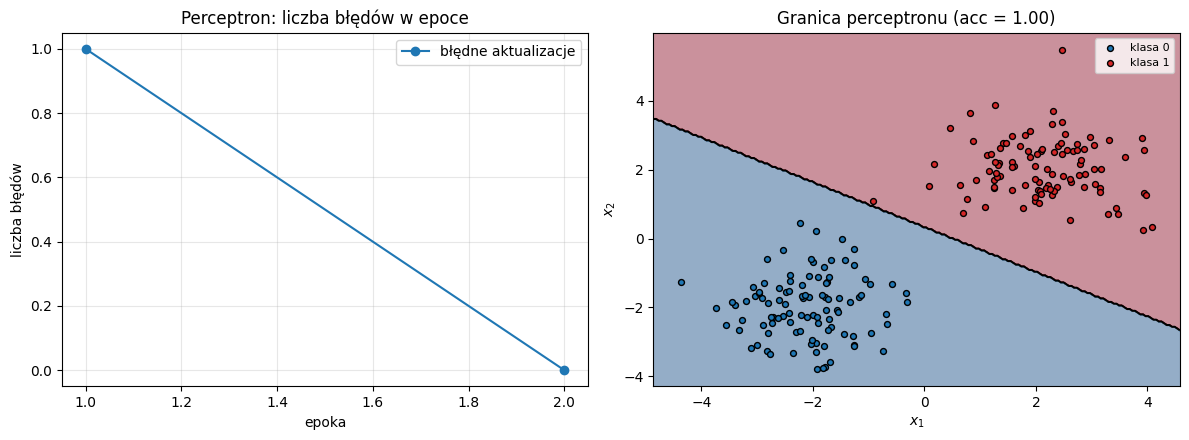

In [111]:
perc = PerceptronRosenblatta(n_wejsc=2, eta=0.1).fit(X_lin, y_lin, epoki=50)
acc = np.mean(perc.predict(X_lin) == y_lin)
print(f"epok: {len(perc.bledy)}, błędy w epokach: {perc.bledy}")
print(f"dokładność: {acc:.3f}, w = {np.round(perc.w, 3)}, b = {perc.b:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(range(1, len(perc.bledy) + 1), perc.bledy, "o-", label="błędne aktualizacje")
ax[0].set_title("Perceptron: liczba błędów w epoce"); ax[0].set_xlabel("epoka"); ax[0].set_ylabel("liczba błędów")
ax[0].grid(alpha=0.3); ax[0].legend()
rysuj_granice(perc.predict, X_lin, y_lin, ax=ax[1], tytul=f"Granica perceptronu (acc = {acc:.2f})")
plt.tight_layout(); plt.show()

### Zadanie 1.2 - Porażka perceptronu na XOR
Funkcja logiczna **XOR** (alternatywa wykluczająca): $0 \oplus 0 = 0$, $0 \oplus 1 = 1$, $1 \oplus 0 = 1$, $1 \oplus 1 = 0$. Narysuj te cztery punkty - **żadna prosta** nie oddzieli klasy 1 od klasy 0. Minsky i Papert (1969, "Perceptrons") pokazali to formalnie, co przyczyniło się do pierwszej "zimy AI".

**Hipoteza (UGŁ_U01):** "Perceptron nie osiągnie 0 błędów na XOR niezależnie od liczby epok; maksymalna dokładność to 75%."

1. Wytrenuj perceptron (100 epok) na 4 punktach XOR (`X_xor`, `y_xor`). Zapisz model w `perc_xor`.
2. Wytrenuj drugi perceptron na "zaszumionym XOR" (`X_xor_szum`, `y_xor_szum` - 400 punktów wokół wierzchołków kwadratu), zapisz w `perc_xor_szum`.
3. Komórka niżej narysuje liczbę błędów w epokach i granice.

**Kryteria sukcesu:** liczba błędów nie spada do zera, dokładność na 4 punktach ≤ 75%, na zaszumionym XOR ok. 50-75%. Hipoteza potwierdzona - wyjaśnij geometrycznie, dlaczego.

In [112]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([0, 1, 1, 0])

rng = np.random.default_rng(SEED)
X_xor_szum = np.repeat(X_xor, 100, axis=0) + rng.normal(scale=0.15, size=(400, 2))
y_xor_szum = np.repeat(y_xor, 100)

perc_xor = PerceptronRosenblatta(2, eta=0.1).fit(X_xor, y_xor, epoki=100)
perc_xor_szum = PerceptronRosenblatta(2, eta=0.1).fit(X_xor_szum, y_xor_szum, epoki=100)
print("XOR:", np.mean(perc_xor.predict(X_xor) == y_xor))
print("Zaszumiony XOR:", np.mean(perc_xor_szum.predict(X_xor_szum) == y_xor_szum))

XOR: 0.5
Zaszumiony XOR: 0.535


XOR (4 punkty): dokładność 0.50, błędy w ostatnich epokach: [1, 3, 2, 3, 2]
XOR zaszumiony: dokładność 0.54


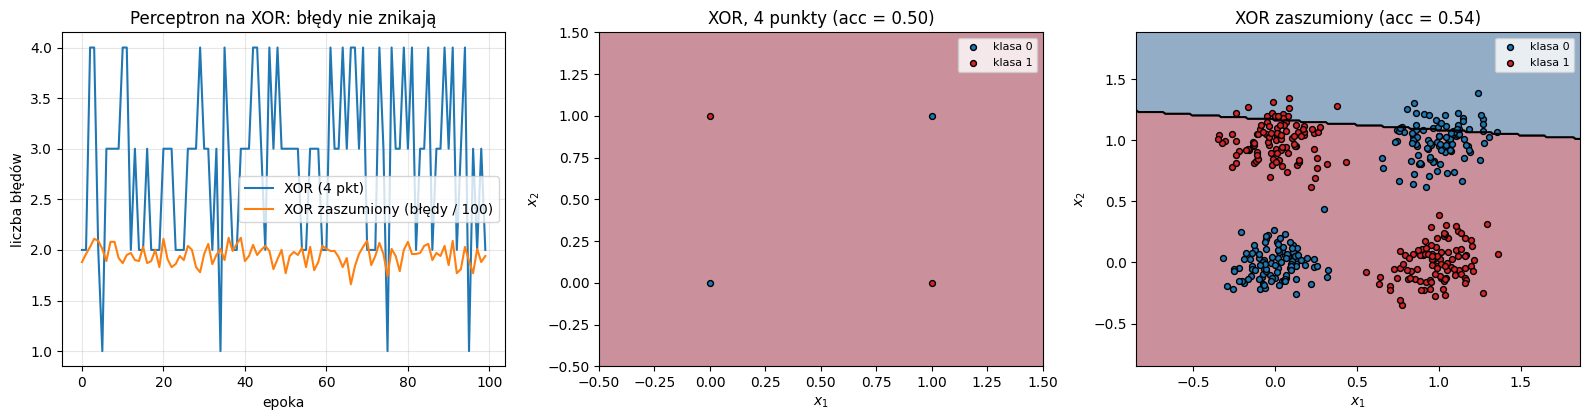

In [113]:
if perc_xor is not None and perc_xor_szum is not None:
    acc4 = np.mean(perc_xor.predict(X_xor) == y_xor)
    acc_s = np.mean(perc_xor_szum.predict(X_xor_szum) == y_xor_szum)
    print(f"XOR (4 punkty): dokładność {acc4:.2f}, błędy w ostatnich epokach: {perc_xor.bledy[-5:]}")
    print(f"XOR zaszumiony: dokładność {acc_s:.2f}")
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
    ax[0].plot(perc_xor.bledy, label="XOR (4 pkt)")
    ax[0].plot(np.array(perc_xor_szum.bledy) / 100, label="XOR zaszumiony (błędy / 100)")
    ax[0].set_title("Perceptron na XOR: błędy nie znikają"); ax[0].set_xlabel("epoka"); ax[0].set_ylabel("liczba błędów")
    ax[0].legend(); ax[0].grid(alpha=0.3)
    rysuj_granice(perc_xor.predict, X_xor, y_xor, ax=ax[1], tytul=f"XOR, 4 punkty (acc = {acc4:.2f})")
    rysuj_granice(perc_xor_szum.predict, X_xor_szum, y_xor_szum, ax=ax[2], tytul=f"XOR zaszumiony (acc = {acc_s:.2f})")
    plt.tight_layout(); plt.show()

## 2. Funkcje aktywacji i ich pochodne

### 2.1 Dlaczego potrzebujemy nieliniowości?
Złożenie warstw liniowych jest liniowe: $W_2(W_1\mathbf x + \mathbf b_1) + \mathbf b_2 = (W_2W_1)\mathbf x + (W_2\mathbf b_1 + \mathbf b_2)$. Bez nieliniowej **funkcji aktywacji** sieć o 100 warstwach byłaby równoważna jednemu perceptronowi i też nie rozwiązałaby XOR. Funkcja skokowa perceptronu jest nieliniowa, ale ma pochodną 0 - **nie da się przez nią propagować gradientu**. Dlatego w sieciach używamy aktywacji różniczkowalnych (W2):

| Funkcja | Wzór | Pochodna | Uwagi |
|---|---|---|---|
| sigmoid | $\sigma(z) = \frac{1}{1+e^{-z}}$ | $\sigma(z)(1-\sigma(z))$, max **0.25** | wyjście $(0,1)$ - warstwa wyjściowa klasyfikacji binarnej; nasycenie |
| tanh | $\tanh z$ | $1 - \tanh^2 z$, max 1 | wyjście $(-1, 1)$, wycentrowane wokół 0 |
| ReLU | $\max(0, z)$ | $1$ dla $z>0$, $0$ dla $z<0$ | standard w warstwach ukrytych; "martwe neurony" |
| LeakyReLU | $\max(\alpha z, z)$ | $1$ lub $\alpha$ | rozwiązuje problem martwych neuronów |
| GELU | $z\,\Phi(z)$ | $\Phi(z) + z\,\varphi(z)$ | gładka ReLU; standard w transformerach |
| softmax | $\frac{e^{z_k}}{\sum_j e^{z_j}}$ | (macierz Jacobiego) | wyjście wieloklasowe - rozkład prawdopodobieństwa |

($\Phi$ - dystrybuanta, $\varphi$ - gęstość standardowego rozkładu normalnego.)

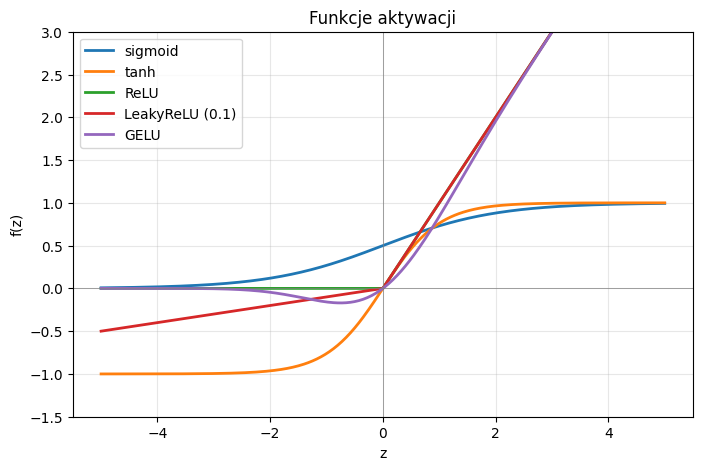

In [114]:
# Implementacje funkcji aktywacji w NumPy
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def tanh(z):
    return np.tanh(z)

def relu(z):
    return np.maximum(0.0, z)

def leaky_relu(z, alfa=0.1):
    return np.where(z > 0, z, alfa * z)

def gelu(z):
    return 0.5 * z * (1.0 + erf(z / np.sqrt(2.0)))       # z * Phi(z), wersja dokładna

AKTYWACJE = {"sigmoid": sigmoid, "tanh": tanh, "ReLU": relu, "LeakyReLU (0.1)": leaky_relu, "GELU": gelu}

z = np.linspace(-5, 5, 401)
plt.figure(figsize=(8, 5))
for nazwa, f in AKTYWACJE.items():
    plt.plot(z, f(z), label=nazwa, lw=2)
plt.axhline(0, color="gray", lw=0.5); plt.axvline(0, color="gray", lw=0.5)
plt.ylim(-1.5, 3); plt.title("Funkcje aktywacji"); plt.xlabel("z"); plt.ylabel("f(z)"); plt.legend(); plt.grid(alpha=0.3); plt.show()

### 2.2 Softmax i stabilność numeryczna
Softmax zamienia wektor **logitów** $\mathbf z$ na rozkład prawdopodobieństwa. Naiwna implementacja $e^{z_k}/\sum_j e^{z_j}$ przepełnia się dla dużych logitów ($e^{1000} = \infty$, a $\infty/\infty$ = `nan`). Trik: softmax jest niezmienniczy względem przesunięcia, więc odejmujemy maksimum: $\text{softmax}(\mathbf z) = \text{softmax}(\mathbf z - \max_k z_k)$. Biblioteki robią to automatycznie - i dlatego w praktyce do funkcji straty podajemy **logity**, a nie prawdopodobieństwa (`from_logits=True` w Keras, `nn.CrossEntropyLoss`/`BCEWithLogitsLoss` w PyTorch).

In [115]:
def softmax_naiwny(z):
    e = np.exp(z)
    return e / e.sum()

def softmax_stabilny(z):
    e = np.exp(z - np.max(z))            # przesunięcie nie zmienia wyniku, a chroni przed overflow
    return e / e.sum()

logity = np.array([2.0, 1.0, 0.1])
print("softmax([2, 1, 0.1])       :", np.round(softmax_stabilny(logity), 4), " suma =", softmax_stabilny(logity).sum())
duze = np.array([1000.0, 1001.0, 1002.0])
with np.errstate(over="ignore", invalid="ignore"):
    print("naiwny dla [1000,1001,1002]:", softmax_naiwny(duze))
print("stabilny                   :", np.round(softmax_stabilny(duze), 4))
print("PyTorch                    :", torch.softmax(torch.tensor(duze), dim=0).numpy().round(4))

softmax([2, 1, 0.1])       : [0.659  0.2424 0.0986]  suma = 1.0
naiwny dla [1000,1001,1002]: [nan nan nan]
stabilny                   : [0.09   0.2447 0.6652]
PyTorch                    : [0.09   0.2447 0.6652]


### Zadanie 2.1 - Pochodne funkcji aktywacji: ręcznie vs autograd
1. Zaimplementuj pochodne `d_sigmoid`, `d_tanh`, `d_relu`, `d_leaky_relu` (z $\alpha = 0.1$), `d_gelu` w NumPy (wzory w tabeli powyżej; $\varphi(z) = e^{-z^2/2}/\sqrt{2\pi}$, $\Phi(z) = \frac12(1 + \text{erf}(z/\sqrt2))$).
2. Komórka sprawdzająca policzy pochodne tych samych funkcji przez **autograd PyTorch** i wypisze maksymalną różnicę, a następnie narysuje pochodne.

**Kryteria sukcesu:** maksymalne różnice < 1e-6 dla wszystkich funkcji. Na wykresie odczytaj: jaka jest maksymalna wartość pochodnej sigmoidu? Gdzie pochodne sigmoid i tanh są bliskie zeru (nasycenie)?

**Wskazówka:** dla ReLU przyjmij pochodną 0 w punkcie $z = 0$ (tak robi PyTorch); dla LeakyReLU w $z=0$ - wartość $\alpha$.

In [116]:
def d_sigmoid(z):
    s = sigmoid(z)
    return s * (1 - s)
def d_tanh(z):
    return 1 - np.tanh(z)**2
def d_relu(z):
    return (np.asarray(z) > 0).astype(float)
def d_leaky_relu(z, alfa=0.1):
    return np.where(np.asarray(z) > 0, 1., alfa)
def d_gelu(z):
    return 0.5 * (1 + erf(z / np.sqrt(2))) + z * np.exp(-z**2 / 2) / np.sqrt(2 * np.pi)

         sigmoid: max |ręczna - autograd| = 5.55e-17
            tanh: max |ręczna - autograd| = 2.77e-16
            ReLU: max |ręczna - autograd| = 0.00e+00
 LeakyReLU (0.1): max |ręczna - autograd| = 0.00e+00
            GELU: max |ręczna - autograd| = 2.22e-16


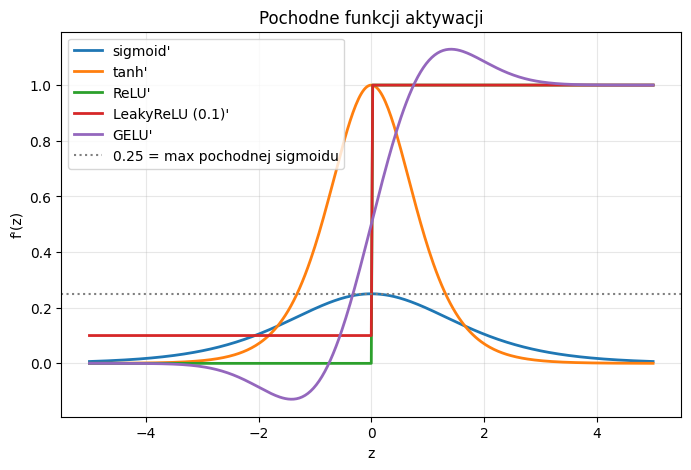

In [117]:
# Komórka sprawdzająca: autograd w PyTorch (float64)
z_t = torch.tensor(z, dtype=torch.float64, requires_grad=True)
torch_akt = {"sigmoid": torch.sigmoid, "tanh": torch.tanh, "ReLU": torch.relu,
             "LeakyReLU (0.1)": lambda t: F.leaky_relu(t, 0.1), "GELU": F.gelu}
reczne = {"sigmoid": d_sigmoid, "tanh": d_tanh, "ReLU": d_relu, "LeakyReLU (0.1)": d_leaky_relu, "GELU": d_gelu}

if d_sigmoid is not None:
    plt.figure(figsize=(8, 5))
    for nazwa, f_t in torch_akt.items():
        z_t.grad = None
        f_t(z_t).sum().backward()                      # suma -> gradient elementowy
        g_auto = z_t.grad.numpy()
        g_rec = reczne[nazwa](z)
        print(f"{nazwa:>16}: max |ręczna - autograd| = {np.abs(g_rec - g_auto).max():.2e}")
        plt.plot(z, g_rec, lw=2, label=f"{nazwa}'")
    plt.axhline(0.25, color="gray", ls=":", label="0.25 = max pochodnej sigmoidu")
    plt.title("Pochodne funkcji aktywacji"); plt.xlabel("z"); plt.ylabel("f'(z)"); plt.legend(); plt.grid(alpha=0.3); plt.show()

### 2.3 Znikający gradient
W sieci o $L$ warstwach gradient straty względem wag pierwszej warstwy jest (z reguły łańcuchowej) **iloczynem** $L$ czynników, w tym pochodnych aktywacji: $\frac{\partial L}{\partial W_1} \propto \prod_{l} f'(z_l)\, W_l$. Jeśli każdy czynnik $f'(z) \le 0.25$ (sigmoid), to po 20 warstwach mamy $0.25^{20} \approx 10^{-12}$ - **pierwsze warstwy praktycznie się nie uczą** (*vanishing gradient*, W2). ReLU ma pochodną 1 dla $z > 0$, więc z poprawną inicjalizacją (He) gradient nie maleje wykładniczo - to jeden z powodów sukcesu głębokich sieci po 2010 r. (obok BatchNorm i połączeń residualnych - W2, L4).

### Zadanie 2.2 - Eksperyment: normy gradientów w głębokiej sieci
**Hipoteza:** "W 20-warstwowej sieci z sigmoidem norma gradientu wag maleje wykładniczo w stronę pierwszych warstw, a z ReLU (inicjalizacja He) pozostaje podobnego rzędu."

Funkcja `zbuduj_gleboka_siec(aktywacja)` jest gotowa (20 warstw ukrytych po 64 neurony; inicjalizacja Xavier dla sigmoid/tanh, He dla ReLU - czyli "najlepsza praktyka" dla każdej aktywacji).
1. Dla każdej aktywacji z listy `["sigmoid", "tanh", "relu"]`: zbuduj sieć, wykonaj przejście w przód na batchu `x_batch`, policz stratę MSE względem `y_batch`, wywołaj `backward()`.
2. Zbierz normy gradientów wag (`m.weight.grad.norm().item()`) wszystkich warstw `nn.Linear` w kolejności od wejścia i zapisz w słowniku `normy[aktywacja] = lista`.

**Kryteria sukcesu:** wykres (skala log) pokazuje spadek o kilka rzędów wielkości dla sigmoidu i w przybliżeniu stały poziom dla ReLU. Hipoteza potwierdzona?

 sigmoid: |grad| warstwa 1 = 2.47e-13, ostatnia = 3.27e+00, stosunek = 7.5e-14
    tanh: |grad| warstwa 1 = 1.51e-01, ostatnia = 2.67e-01, stosunek = 5.6e-01
    relu: |grad| warstwa 1 = 3.52e-01, ostatnia = 2.55e-01, stosunek = 1.4e+00


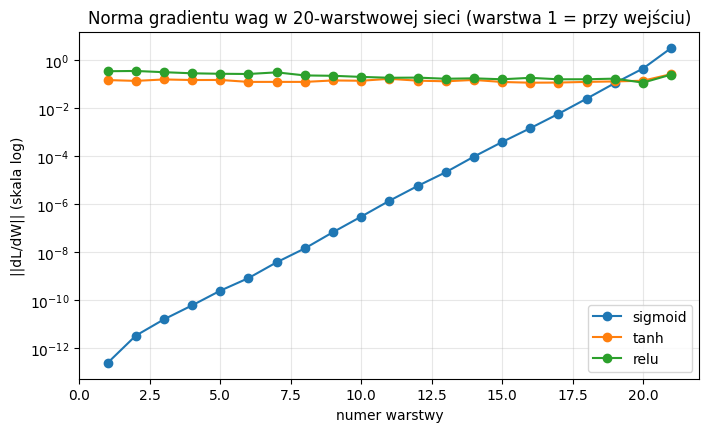

In [118]:
def zbuduj_gleboka_siec(aktywacja, L=20, szer=64, seed=0):
    torch.manual_seed(seed)
    akt = {"sigmoid": nn.Sigmoid, "tanh": nn.Tanh, "relu": nn.ReLU}[aktywacja]
    warstwy = []
    for _ in range(L):
        lin = nn.Linear(szer, szer)
        if aktywacja == "relu":
            nn.init.kaiming_normal_(lin.weight, nonlinearity="relu")   # inicjalizacja He
        else:
            nn.init.xavier_normal_(lin.weight)                         # inicjalizacja Xavier/Glorot
        nn.init.zeros_(lin.bias)
        warstwy += [lin, akt()]
    warstwy.append(nn.Linear(szer, 1))                                  # wyjście
    return nn.Sequential(*warstwy)

torch.manual_seed(SEED)
x_batch = torch.randn(256, 64)
y_batch = torch.randn(256, 1)

normy = {}
for aktywacja in ["sigmoid", "tanh", "relu"]:
    model_gleboki = zbuduj_gleboka_siec(aktywacja)
    strata_gleboka = nn.functional.mse_loss(model_gleboki(x_batch), y_batch)
    model_gleboki.zero_grad()
    strata_gleboka.backward()
    normy[aktywacja] = [warstwa.weight.grad.norm().item()
                        for warstwa in model_gleboki.modules() if isinstance(warstwa, nn.Linear)]

if normy:
    plt.figure(figsize=(8, 4.5))
    for akt_nazwa, nr in normy.items():
        plt.semilogy(range(1, len(nr) + 1), nr, "o-", label=akt_nazwa)
        print(f"{akt_nazwa:>8}: |grad| warstwa 1 = {nr[0]:.2e}, ostatnia = {nr[-1]:.2e}, stosunek = {nr[0] / nr[-1]:.1e}")
    plt.title("Norma gradientu wag w 20-warstwowej sieci (warstwa 1 = przy wejściu)")
    plt.xlabel("numer warstwy"); plt.ylabel("||dL/dW|| (skala log)"); plt.legend(); plt.grid(alpha=0.3, which="both"); plt.show()

## 3. MLP od zera z ręczną propagacją wsteczną (XOR)

### 3.1 Architektura
Rozwiążemy XOR siecią z jedną **warstwą ukrytą** (2 wejścia -> 4 neurony tanh -> 1 neuron sigmoid). Dla batcha $X$ o kształcie $(n, 2)$:
$$Z_1 = XW_1 + \mathbf b_1,\quad A_1 = \tanh(Z_1),\quad Z_2 = A_1W_2 + b_2,\quad \hat{\mathbf y} = A_2 = \sigma(Z_2).$$
Kształty: $W_1$ - `(2, 4)`, $\mathbf b_1$ - `(4,)`, $W_2$ - `(4, 1)`, $b_2$ - `(1,)`. Razem $2\cdot4+4+4\cdot1+1 = 17$ parametrów.

**Funkcja straty** - entropia krzyżowa binarna (BCE, W3):
$$L = -\frac1n\sum_{i=1}^n\big[y_i\log\hat y_i + (1-y_i)\log(1-\hat y_i)\big].$$

### 3.2 Propagacja wsteczna - wyprowadzenie
Idziemy od straty do wejść, stosując regułę łańcuchową. Oznaczmy $\delta_2 = \partial L/\partial Z_2$, $\delta_1 = \partial L/\partial Z_1$.

1. **Wyjście (sigmoid + BCE)** - piękne uproszczenie: $\frac{\partial L}{\partial \hat y}\cdot\sigma'(z) = \frac{\hat y - y}{\hat y(1-\hat y)}\cdot\hat y(1-\hat y)$, więc
$$\delta_2 = \frac{1}{n}(A_2 - Y).$$
2. **Gradienty warstwy 2:** $\;\frac{\partial L}{\partial W_2} = A_1^\top\delta_2, \qquad \frac{\partial L}{\partial b_2} = \sum_i \delta_{2,i}$ (suma po batchu).
3. **Propagacja do warstwy ukrytej:** $\;\frac{\partial L}{\partial A_1} = \delta_2W_2^\top$, a pochodna tanh to $1 - A_1^2$:
$$\delta_1 = (\delta_2W_2^\top)\odot(1 - A_1^2).$$
4. **Gradienty warstwy 1:** $\;\frac{\partial L}{\partial W_1} = X^\top\delta_1, \qquad \frac{\partial L}{\partial \mathbf b_1} = \sum_i\delta_{1,i}.$

Reguła ogólna dla warstwy gęstej $Z = AW + \mathbf b$: **gradient po wagach = (wejście warstwy)$^\top$ · (gradient po wyjściu)**; gradient po wejściu = (gradient po wyjściu) · $W^\top$. Kontrola kształtów to najlepszy test: $\partial L/\partial W$ musi mieć kształt $W$.

Dokładnie to robi autograd (`loss.backward()`) - automatycznie, dla dowolnego grafu.

In [119]:
X_x = X_xor.copy()                       # (4, 2)
Y_x = y_xor.reshape(-1, 1).astype(float) # (4, 1) - kolumna, żeby kształty pasowały do A2

def init_params(n_wej=2, n_ukr=4, n_wyj=1, seed=1):
    rng = np.random.default_rng(seed)
    return {"W1": rng.normal(0, 1.0, (n_wej, n_ukr)), "b1": np.zeros(n_ukr),
            "W2": rng.normal(0, 1.0, (n_ukr, n_wyj)), "b2": np.zeros(n_wyj)}

def forward(params, X):
    Z1 = X @ params["W1"] + params["b1"]      # (n, n_ukr)
    A1 = np.tanh(Z1)
    Z2 = A1 @ params["W2"] + params["b2"]     # (n, 1)
    A2 = sigmoid(Z2)
    cache = {"X": X, "A1": A1, "A2": A2}     # zapamiętujemy wartości potrzebne w backward
    return A2, cache

def bce(A2, Y, eps=1e-12):
    # eps chroni przed log(0)
    return float(-np.mean(Y * np.log(A2 + eps) + (1 - Y) * np.log(1 - A2 + eps)))

params = init_params()
A2, _ = forward(params, X_x)
print("predykcje przed treningiem:", A2.ravel().round(3), " strata BCE =", round(bce(A2, Y_x), 4))
print("liczba parametrów:", sum(v.size for v in params.values()))

predykcje przed treningiem: [0.5   0.659 0.464 0.554]  strata BCE = 0.6712
liczba parametrów: 17


### Zadanie 3.1 - Implementacja `backward` i trening MLP na XOR
Uzupełnij funkcję `backward(params, cache, Y)`, która zwraca słownik gradientów `{"W1": ..., "b1": ..., "W2": ..., "b2": ...}` według wzorów z sekcji 3.2. Pętla treningowa (spadek gradientu, full-batch) jest gotowa w następnej komórce.

**Kryteria sukcesu:** strata spada poniżej 0.05, predykcje po zaokrągleniu to `[0, 1, 1, 0]`, granica decyzyjna oddziela przekątne kwadratu. Każdy gradient ma kształt odpowiadającego mu parametru.

**Wskazówki:** `cache["A1"]`, `cache["A2"]`, `cache["X"]`; liczba próbek `n = Y.shape[0]`; sumy po batchu: `.sum(axis=0)`.

In [120]:
def backward(params, cache, Y):
    X, A1, A2 = cache["X"], cache["A1"], cache["A2"]
    n = Y.shape[0]
    delta2 = (A2 - Y) / n
    dW2 = A1.T @ delta2
    db2 = delta2.sum(axis=0)
    delta1 = (delta2 @ params["W2"].T) * (1 - A1**2)
    dW1 = X.T @ delta1
    db1 = delta1.sum(axis=0)
    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

predykcje po treningu: [0.    0.999 0.999 0.001] -> [0 1 1 0]  (cel: [0 1 1 0])
końcowa strata BCE: 0.00047


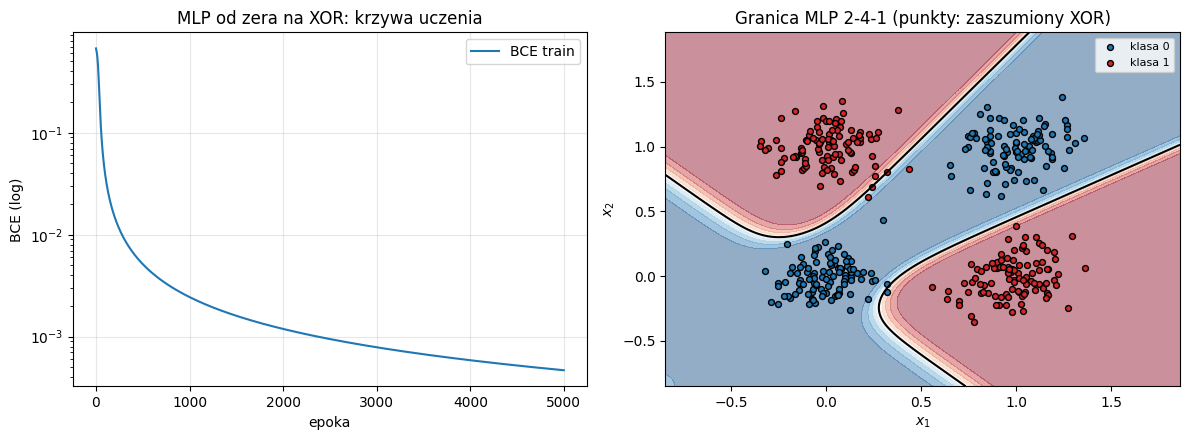

In [121]:
EPOKI_XOR = 2000 if SZYBKI_TRYB else 5000
lr_xor = 1.0
params = init_params()
hist_xor = []
for ep in range(EPOKI_XOR):
    A2, cache = forward(params, X_x)           # 1) forward
    hist_xor.append(bce(A2, Y_x))              # 2) strata
    grads = backward(params, cache, Y_x)       # 3) backward (ręcznie!)
    for k in params:                           # 4) krok spadku gradientu
        params[k] -= lr_xor * grads[k]

A2, _ = forward(params, X_x)
print("predykcje po treningu:", A2.ravel().round(3), "->", (A2.ravel() > 0.5).astype(int), " (cel: [0 1 1 0])")
print("końcowa strata BCE:", round(hist_xor[-1], 5))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(hist_xor, label="BCE train"); ax[0].set_yscale("log")
ax[0].set_title("MLP od zera na XOR: krzywa uczenia"); ax[0].set_xlabel("epoka"); ax[0].set_ylabel("BCE (log)")
ax[0].legend(); ax[0].grid(alpha=0.3)
rysuj_granice(lambda P: forward(params, P)[0].ravel(), X_xor_szum, y_xor_szum, ax=ax[1],
              tytul="Granica MLP 2-4-1 (punkty: zaszumiony XOR)")
plt.tight_layout(); plt.show()

### Zadanie 3.2 - Gradient check ręcznego backpropu
Ręcznie napisany backprop **zawsze** trzeba zweryfikować. Wykorzystaj technikę z L1 (Zadanie 2.2): dla każdego parametru i każdego jego elementu policz różnicę centralną straty $\frac{L(\theta + h) - L(\theta - h)}{2h}$ i porównaj z wynikiem `backward`.

Uzupełnij `gradient_check(params, X, Y, h)`: zwraca słownik `{nazwa: błąd_względny}` dla każdego parametru, gdzie błąd względny $= \frac{\|g_{num} - g_{bp}\|}{\|g_{num}\| + \|g_{bp}\|}$.

**Kryteria sukcesu:** wszystkie błędy względne < 1e-7 (dla świeżo zainicjalizowanych parametrów, `float64`). Następnie celowo "zepsuj" backprop (np. zamień `1 - A1**2` na `1 - A1` w kopii funkcji) i zobacz, jak gradient check wychwytuje błąd - opcjonalnie.

**Wskazówka:** iteruj po elementach tablicy przez `np.ndindex(p.shape)`; modyfikuj kopię parametrów (`{k: v.copy() ...}`), żeby nie zepsuć oryginału.

In [122]:
def gradient_check(params, X, Y, h=1e-5):
    _, cache = forward(params, X)
    g_bp = backward(params, cache, Y)                # gradienty z ręcznego backpropu
    bledy = {}
    for nazwa, p in params.items():
        g_num = np.zeros_like(p)
        for idx in np.ndindex(p.shape):
            plus = {k: v.copy() for k, v in params.items()}
            minus = {k: v.copy() for k, v in params.items()}
            plus[nazwa][idx] += h
            minus[nazwa][idx] -= h
            g_num[idx] = (bce(forward(plus, X)[0], Y) - bce(forward(minus, X)[0], Y)) / (2 * h)
        bledy[nazwa] = np.linalg.norm(g_num - g_bp[nazwa]) / (np.linalg.norm(g_num) + np.linalg.norm(g_bp[nazwa]) + 1e-15)
    return bledy

p_test = init_params(seed=7)
for nazwa, blad in gradient_check(p_test, X_x, Y_x).items():
    print(f"{nazwa}: błąd względny = {blad:.2e}  {'OK' if blad < 1e-7 else 'SPRAWDŹ!'}")

W1: błąd względny = 7.77e-11  OK
b1: błąd względny = 2.91e-11  OK
W2: błąd względny = 2.96e-11  OK
b2: błąd względny = 2.70e-11  OK


## 4. MLP w Keras

Teraz zobaczymy, jak to samo (i więcej) robi się w kilku liniach w **Keras 3** (wysokopoziomowe API działające na TensorFlow, JAX lub PyTorch - u nas backend TensorFlow). Keras przejmuje: inicjalizację wag (domyślnie Glorot/Xavier uniform), backprop (autograd TF), pętlę treningową z mini-batchami, liczenie metryk i walidację.

Trzy kroki w Keras (W3):
1. **Zbudowanie** modelu - `Sequential` (stos warstw) lub **Functional API** (dowolny graf).
2. **`compile`** - wybór optymalizatora, funkcji straty i metryk.
3. **`fit`** - trening; `evaluate` / `predict` - ocena i predykcja.

### 4.1 Dane: dwa półksiężyce (`make_moons`)
Dwie przeplatające się klasy w kształcie półksiężyców - nieliniowo separowalne, więc perceptron sobie nie poradzi, a MLP tak. Dzielimy dane na train i walidację (stratyfikacja - równe proporcje klas). Cechy mają już skalę rzędu 1, więc standaryzacja nie jest konieczna (w L3 będzie obowiązkowa).

train: (750, 2)  walidacja: (250, 2)  proporcje klas (train): [375 375]


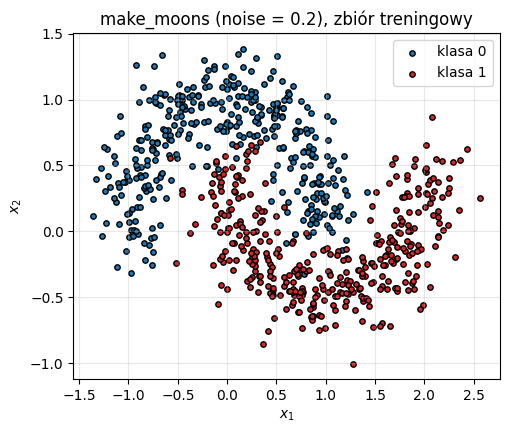

In [123]:
N_PROBEK = 300 if SZYBKI_TRYB else 1000
EPOKI_KERAS = 5 if SZYBKI_TRYB else 150

X_m, y_m = make_moons(n_samples=N_PROBEK, noise=0.2, random_state=SEED)
X_m = X_m.astype(np.float32)
Xm_tr, Xm_va, ym_tr, ym_va = train_test_split(X_m, y_m, test_size=0.25, random_state=SEED, stratify=y_m)
print("train:", Xm_tr.shape, " walidacja:", Xm_va.shape, " proporcje klas (train):", np.bincount(ym_tr))

plt.figure(figsize=(5.5, 4.5))
for kl, kol in zip([0, 1], ["tab:blue", "tab:red"]):
    plt.scatter(Xm_tr[ym_tr == kl, 0], Xm_tr[ym_tr == kl, 1], color=kol, edgecolors="k", s=15, label=f"klasa {kl}")
plt.title("make_moons (noise = 0.2), zbiór treningowy"); plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.legend(); plt.grid(alpha=0.3); plt.show()

### 4.2 Sequential API
`keras.Sequential` - lista warstw wykonywanych po kolei. `keras.Input(shape=(2,))` deklaruje kształt **jednej próbki** (bez wymiaru batcha). Warstwa `Dense(16, activation="relu")` to $\text{ReLU}(XW + \mathbf b)$ z 16 neuronami.

Dopasowanie warstwy wyjściowej i straty do zadania (W3): **klasyfikacja binarna** -> 1 neuron z `sigmoid` + `binary_crossentropy`. (Wieloklasowa: $K$ neuronów + `softmax` + `sparse_categorical_crossentropy`; regresja: 1 neuron liniowy + `mse` - L3.)

`model.summary()` pokazuje warstwy, kształty wyjść (`None` = dowolny rozmiar batcha) i **liczbę parametrów**.

In [124]:
model_seq = keras.Sequential([
    keras.Input(shape=(2,)),                              # próbka = 2 cechy
    layers.Dense(16, activation="relu", name="ukryta_1"),
    layers.Dense(16, activation="relu", name="ukryta_2"),
    layers.Dense(1, activation="sigmoid", name="wyjscie"),  # p(klasa = 1)
], name="mlp_sequential")
model_seq.summary()

Model: "mlp_sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ukryta_1 (Dense)                │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ukryta_2 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ wyjscie (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

czas treningu: 30.7 s
walidacja: strata = 0.0460, dokładność = 0.9800


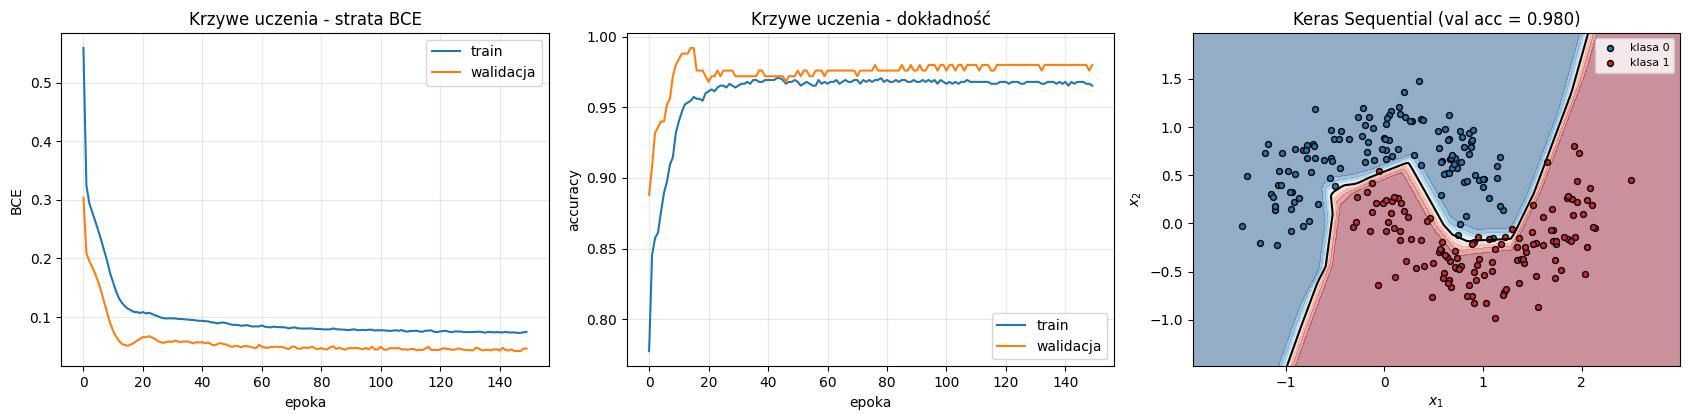

In [95]:
model_seq.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01),
                  loss="binary_crossentropy",
                  metrics=["accuracy"])

t0 = time.perf_counter()
hist_seq = model_seq.fit(Xm_tr, ym_tr, validation_data=(Xm_va, ym_va),
                         epochs=EPOKI_KERAS, batch_size=32, verbose=0)   # verbose=0: bez paska postępu
print(f"czas treningu: {time.perf_counter() - t0:.1f} s")
strata_va, acc_va = model_seq.evaluate(Xm_va, ym_va, verbose=0)
print(f"walidacja: strata = {strata_va:.4f}, dokładność = {acc_va:.4f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
ax[0].plot(hist_seq.history["loss"], label="train"); ax[0].plot(hist_seq.history["val_loss"], label="walidacja")
ax[0].set_title("Krzywe uczenia - strata BCE"); ax[0].set_xlabel("epoka"); ax[0].set_ylabel("BCE"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(hist_seq.history["accuracy"], label="train"); ax[1].plot(hist_seq.history["val_accuracy"], label="walidacja")
ax[1].set_title("Krzywe uczenia - dokładność"); ax[1].set_xlabel("epoka"); ax[1].set_ylabel("accuracy"); ax[1].legend(); ax[1].grid(alpha=0.3)
rysuj_granice(lambda P: model_seq.predict(P, verbose=0, batch_size=4096).ravel(), Xm_va, ym_va, ax=ax[2],
              tytul=f"Keras Sequential (val acc = {acc_va:.3f})")
plt.tight_layout(); plt.show()

**Co obserwować:** krzywe train i walidacji idą blisko siebie (brak silnego przeuczenia - mały model, sporo danych). Granica jest gładka i podąża za kształtem półksiężyców. Kolory tła pokazują **pewność** modelu - daleko od granicy prawdopodobieństwo jest bliskie 0 lub 1.

Typowe błędy w Keras: `Dense(2, activation="sigmoid")` z `binary_crossentropy` przy etykietach 0/1 (błąd kształtu), `Dense(1)` bez sigmoidu z `binary_crossentropy` (strata liczona na nie-prawdopodobieństwach - trzeba wtedy `from_logits=True`), brak `keras.Input` (model nie zna kształtu, `summary()` nie pokaże parametrów przed pierwszym wywołaniem).

### Zadanie 4.1 - Ręczne liczenie liczby parametrów
Warstwa gęsta z $n_{in}$ wejściami i $n_{out}$ neuronami ma macierz wag $n_{in}\times n_{out}$ i wektor biasów $n_{out}$, czyli
$$P = n_{in}\cdot n_{out} + n_{out} = (n_{in} + 1)\, n_{out}$$
parametrów (W2). Funkcje aktywacji nie mają parametrów.

1. Napisz `liczba_parametrow(rozmiary)`, gdzie `rozmiary` to lista szerokości warstw od wejścia do wyjścia, np. `[2, 16, 16, 1]`. Funkcja zwraca krotkę `(lista_parametrów_na_warstwę, suma)`.
2. Porównaj wynik z `model_seq.count_params()` i z `[w.count_params() for w in model_seq.layers]`.
3. Zbuduj w Keras (Sequential) model `model_duzy` o architekturze `[2, 64, 32, 8, 1]` (ReLU, sigmoid na wyjściu) i też porównaj.

**Kryteria sukcesu:** wartości ręczne i z Keras są identyczne. Odpowiedz: ile parametrów miałaby jedna warstwa `Dense(512)` na wejściu z obrazem 28x28 (spłaszczonym)?

In [96]:
def liczba_parametrow(rozmiary):
    parametry = [(a + 1) * b for a, b in zip(rozmiary[:-1], rozmiary[1:])]
    return parametry, sum(parametry)
model_duzy = keras.Sequential([
    keras.Input(shape=(2,)), layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"), layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

if liczba_parametrow is not None:
    print("model_seq  ręcznie:", liczba_parametrow([2, 16, 16, 1]),
          "| Keras:", [w.count_params() for w in model_seq.layers], model_seq.count_params())
if liczba_parametrow is not None and model_duzy is not None:
    print("model_duzy ręcznie:", liczba_parametrow([2, 64, 32, 8, 1]),
          "| Keras:", [w.count_params() for w in model_duzy.layers], model_duzy.count_params())
    print("Dense(512) na obrazie 28x28:", liczba_parametrow([28 * 28, 512])[1], "parametrów")

model_seq  ręcznie: ([48, 272, 17], 337) | Keras: [48, 272, 17] 337
model_duzy ręcznie: ([192, 2080, 264, 9], 2545) | Keras: [192, 2080, 264, 9] 2545
Dense(512) na obrazie 28x28: 401920 parametrów


### 4.3 Functional API
Sequential pozwala tylko na liniowy stos warstw. **Functional API** traktuje warstwy jak funkcje wywoływane na tensorach symbolicznych - można budować dowolne grafy: wiele wejść/wyjść, rozgałęzienia, **połączenia pomijające** (skip connections, zapowiedź ResNet z W2/L4). Model definiujemy przez wskazanie wejść i wyjść: `keras.Model(inputs, outputs)`.

Poniżej przykład z połączeniem, którego nie da się zapisać w Sequential: wejście jest doklejane (`Concatenate`) do wyjścia drugiej warstwy ukrytej.

In [97]:
wej = keras.Input(shape=(2,), name="wejscie")
h1 = layers.Dense(32, activation="relu", name="ukryta_1")(wej)          # warstwa wywołana na tensorze
h2 = layers.Dense(32, activation="relu", name="ukryta_2")(h1)
polacz = layers.Concatenate(name="skip")([wej, h2])                      # połączenie pomijające: [x, h2]
wyj = layers.Dense(1, activation="sigmoid", name="wyjscie")(polacz)
model_func_demo = keras.Model(inputs=wej, outputs=wyj, name="mlp_functional_skip")
model_func_demo.summary()
# Zwróć uwagę: warstwa wyjściowa ma (32 + 2 + 1) * 1 = 35 parametrów - wejście jest doklejone

Model: "mlp_functional_skip"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ wejscie             │ (None, 2)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ukryta_1 (Dense)    │ (None, 32)        │         96 │ wejscie[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ukryta_2 (Dense)    │ (None, 32)        │      1,056 │ ukryta_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip (Concatenate)  │ (None, 34)        │          0 │ wejscie[0][0],    │
│                     │                   │            │ ukryta_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ wyjscie (Dense)     │ (None, 1)         │         35 │ skip[0][0]        │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,187 (4.64 KB)

 Trainable params: 1,187 (4.64 KB)

 Non-trainable params: 0 (0.00 B)

### Zadanie 4.2 - Functional API na danych `make_circles`
Dane `make_circles`: jedno koło wewnątrz drugiego - klasycznie nieseparowalne liniowo.
1. Zbuduj model `model_c` w **Functional API**: wejście 2 -> `Dense(16, tanh)` -> `Dense(8, tanh)` -> `Dense(1, sigmoid)`.
2. Skompiluj (Adam, lr = 0.01, `binary_crossentropy`, metryka `accuracy`) i wytrenuj na `Xc_tr, yc_tr` z walidacją na `Xc_va, yc_va` przez `EPOKI_KERAS` epok (batch 32, `verbose=0`). Historię zapisz w `hist_c`.
3. Komórka niżej narysuje krzywe uczenia i granicę.

**Kryteria sukcesu (pełny tryb):** dokładność walidacyjna ≥ 0.97; granica decyzyjna ma kształt zbliżony do okręgu.

**Pytanie:** jaką cechę należałoby dodać ręcznie, żeby wystarczył model liniowy? (Pomyśl o $x_1^2 + x_2^2$.)

In [98]:
X_c, y_c = make_circles(n_samples=N_PROBEK, noise=0.1, factor=0.5, random_state=SEED)
X_c = X_c.astype(np.float32)
Xc_tr, Xc_va, yc_tr, yc_va = train_test_split(X_c, y_c, test_size=0.25, random_state=SEED, stratify=y_c)

inp_c = keras.Input(shape=(2,))
h_c = layers.Dense(16, activation="tanh")(inp_c)
h_c = layers.Dense(8, activation="tanh")(h_c)
out_c = layers.Dense(1, activation="sigmoid")(h_c)
model_c = keras.Model(inp_c, out_c)
model_c.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01),
                loss="binary_crossentropy", metrics=["accuracy"])
hist_c = model_c.fit(Xc_tr, yc_tr, epochs=EPOKI_KERAS, batch_size=32,
                     validation_data=(Xc_va, yc_va), verbose=0)

make_circles: dokładność walidacyjna = 0.9880


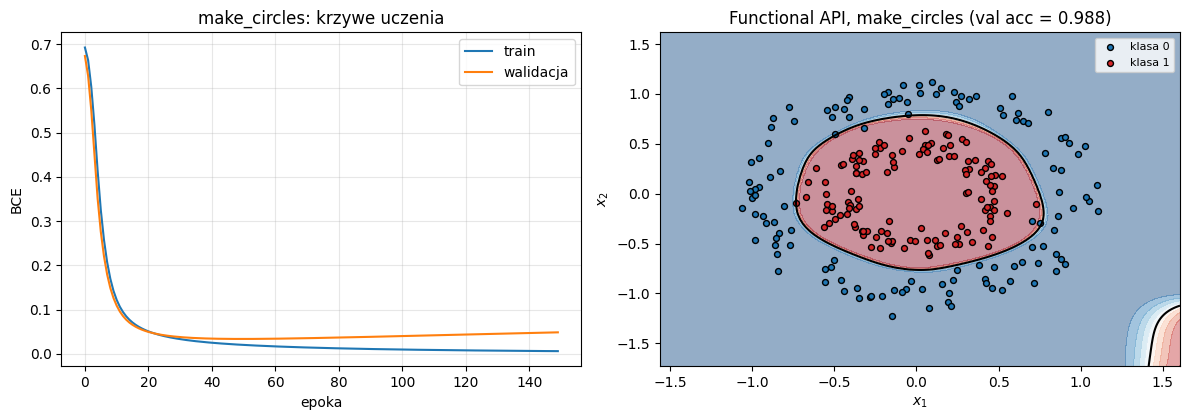

In [99]:
if model_c is not None and hist_c is not None:
    _, acc_c = model_c.evaluate(Xc_va, yc_va, verbose=0)
    print(f"make_circles: dokładność walidacyjna = {acc_c:.4f}")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
    ax[0].plot(hist_c.history["loss"], label="train"); ax[0].plot(hist_c.history["val_loss"], label="walidacja")
    ax[0].set_title("make_circles: krzywe uczenia"); ax[0].set_xlabel("epoka"); ax[0].set_ylabel("BCE"); ax[0].legend(); ax[0].grid(alpha=0.3)
    rysuj_granice(lambda P: model_c.predict(P, verbose=0, batch_size=4096).ravel(), Xc_va, yc_va, ax=ax[1],
                  tytul=f"Functional API, make_circles (val acc = {acc_c:.3f})")
    plt.tight_layout(); plt.show()

## 5. Ten sam model w PyTorch

PyTorch jest bardziej "niskopoziomowy" niż Keras: model definiujemy jako klasę, a **pętlę treningową piszemy sami**. Daje to pełną kontrolę (i jest standardem w badaniach naukowych), ale wymaga więcej kodu. Elementy:

1. **`Dataset` / `TensorDataset`** - dostęp do pojedynczych próbek; **`DataLoader`** - dzieli dane na mini-batche, tasuje (`shuffle=True` dla train), opcjonalnie ładuje równolegle.
2. **`nn.Module`** - klasa modelu: w `__init__` tworzymy warstwy (ich parametry są automatycznie rejestrowane i widoczne w `model.parameters()`), w `forward` opisujemy przejście w przód.
3. **Funkcja straty** - dla klasyfikacji binarnej `nn.BCEWithLogitsLoss` przyjmuje **logity** (bez sigmoidu na wyjściu!) - łączy sigmoid i BCE w jedną, numerycznie stabilną operację.
4. **Optymalizator** - `torch.optim.Adam(model.parameters(), lr=...)`.
5. **Pętla:** `model.train()` -> dla każdego batcha: `zero_grad()` -> forward -> strata -> `backward()` -> `step()`; ewaluacja w `model.eval()` i `torch.no_grad()`.

`model.train()` / `model.eval()` przełączają zachowanie warstw takich jak Dropout i BatchNorm (L3) - w dzisiejszym modelu nic nie zmieniają, ale to dobry nawyk od początku.

Różnice względem Keras, które mogą dać nieco inne wyniki: inna domyślna inicjalizacja wag (PyTorch: Kaiming uniform, Keras: Glorot uniform), brak wbudowanego liczenia metryk.

In [100]:
class MLP(nn.Module):
    def __init__(self, n_wej=2, n_ukr=16, n_warstw=2):
        super().__init__()
        warstwy, wej = [], n_wej
        for _ in range(n_warstw):                       # n_warstw warstw ukrytych z ReLU
            warstwy += [nn.Linear(wej, n_ukr), nn.ReLU()]
            wej = n_ukr
        warstwy.append(nn.Linear(wej, 1))               # wyjście: 1 logit (bez sigmoidu!)
        self.siec = nn.Sequential(*warstwy)

    def forward(self, x):
        return self.siec(x).squeeze(-1)                 # (batch, 1) -> (batch,)

torch.manual_seed(SEED)
model_pt = MLP().to(DEVICE)
print(model_pt)
print("liczba parametrów:", sum(p.numel() for p in model_pt.parameters()), "(porównaj z model_seq w Keras)")

# Dane -> tensory float32 -> TensorDataset -> DataLoader
ds_tr = TensorDataset(torch.tensor(Xm_tr), torch.tensor(ym_tr, dtype=torch.float32))
ds_va = TensorDataset(torch.tensor(Xm_va), torch.tensor(ym_va, dtype=torch.float32))
loader_tr = DataLoader(ds_tr, batch_size=32, shuffle=True)     # tasowanie co epokę
loader_va = DataLoader(ds_va, batch_size=256, shuffle=False)   # walidacja: bez tasowania
xb, yb = next(iter(loader_tr))
print("przykładowy batch:", tuple(xb.shape), tuple(yb.shape), xb.dtype)

MLP(
  (siec): Sequential(
    (0): Linear(in_features=2, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)
liczba parametrów: 337 (porównaj z model_seq w Keras)
przykładowy batch: (32, 2) (32,) torch.float32


### Zadanie 5.1 - Pętla treningowa w PyTorch
Uzupełnij dwie funkcje:
1. `trenuj_epoke(model, loader, opt, loss_fn)` - tryb `model.train()`; dla każdego batcha: przenieś dane na `DEVICE`, wyzeruj gradienty, policz logity i stratę, `backward()`, `opt.step()`. Zwróć **średnią stratę** i **dokładność** na epoce (ważone liczbą próbek w batchu).
2. `ewaluuj(model, loader, loss_fn)` - tryb `model.eval()` i blok `torch.no_grad()`; zwraca średnią stratę i dokładność.

Predykcja klasy z logitu: `logit > 0` (równoważne $\sigma(\text{logit}) > 0.5$).

Pętla po epokach, wykresy i granica są gotowe poniżej.

**Kryteria sukcesu (pełny tryb):** dokładność walidacyjna ok. 0.96-0.98 - porównywalna z modelem Keras z sekcji 4.2; krzywe uczenia podobne.

**Typowe błędy do uniknięcia:** brak `opt.zero_grad()` (akumulacja gradientów - L1!), sigmoid w `forward` razem z `BCEWithLogitsLoss` (podwójny sigmoid), etykiety typu `long` zamiast `float` dla BCE, `loss` zamiast `loss.item()` przy sumowaniu (trzymanie całego grafu w pamięci).

In [101]:
def trenuj_epoke(model, loader, opt, loss_fn):
    model.train()
    suma_straty, poprawne, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        opt.zero_grad()
        logity = model(xb)
        loss = loss_fn(logity, yb)
        loss.backward()
        opt.step()
        licz = len(yb)
        suma_straty += loss.item() * licz
        poprawne += ((logity > 0) == (yb > 0.5)).sum().item()
        n += licz
    return suma_straty / n, poprawne / n


def ewaluuj(model, loader, loss_fn):
    model.eval()
    suma_straty, poprawne, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logity = model(xb)
            loss = loss_fn(logity, yb)
            licz = len(yb)
            suma_straty += loss.item() * licz
            poprawne += ((logity > 0) == (yb > 0.5)).sum().item()
            n += licz
    return suma_straty / n, poprawne / n

epoka   1: loss 0.5330 | val_loss 0.3278 | val_acc 0.8520
epoka  31: loss 0.0823 | val_loss 0.0900 | val_acc 0.9600
epoka  61: loss 0.0750 | val_loss 0.0500 | val_acc 0.9760
epoka  91: loss 0.0756 | val_loss 0.0355 | val_acc 0.9880
epoka 121: loss 0.0737 | val_loss 0.0367 | val_acc 0.9880
epoka 150: loss 0.0683 | val_loss 0.0356 | val_acc 0.9880
czas: 9.7 s


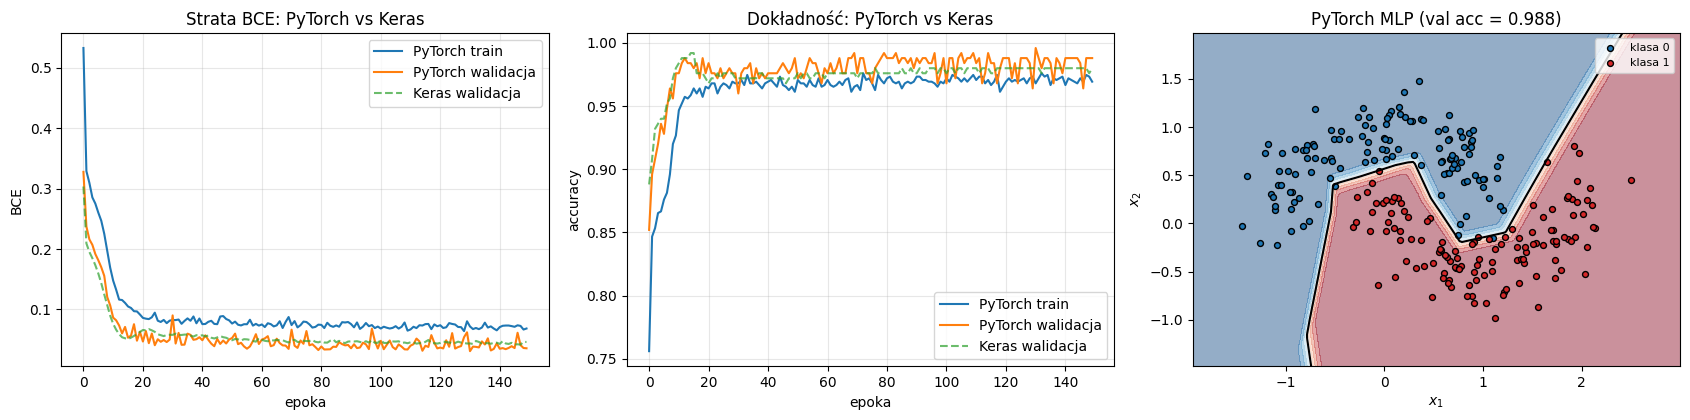

In [102]:
torch.manual_seed(SEED)
model_pt = MLP().to(DEVICE)
opt = torch.optim.Adam(model_pt.parameters(), lr=0.01)
loss_fn = nn.BCEWithLogitsLoss()

hist_pt = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}
t0 = time.perf_counter()
for ep in range(EPOKI_KERAS):
    l_tr, a_tr = trenuj_epoke(model_pt, loader_tr, opt, loss_fn)
    l_va, a_va = ewaluuj(model_pt, loader_va, loss_fn)
    for k, v in zip(hist_pt, [l_tr, l_va, a_tr, a_va]):
        hist_pt[k].append(v)
    if ep % max(1, EPOKI_KERAS // 5) == 0 or ep == EPOKI_KERAS - 1:
        print(f"epoka {ep + 1:3d}: loss {l_tr:.4f} | val_loss {l_va:.4f} | val_acc {a_va:.4f}")
print(f"czas: {time.perf_counter() - t0:.1f} s")

def predict_pt(P):
    model_pt.eval()
    with torch.no_grad():
        return torch.sigmoid(model_pt(torch.tensor(P, device=DEVICE))).cpu().numpy()   # logit -> p

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
ax[0].plot(hist_pt["loss"], label="PyTorch train"); ax[0].plot(hist_pt["val_loss"], label="PyTorch walidacja")
ax[0].plot(hist_seq.history["val_loss"], "--", alpha=0.7, label="Keras walidacja")
ax[0].set_title("Strata BCE: PyTorch vs Keras"); ax[0].set_xlabel("epoka"); ax[0].set_ylabel("BCE"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(hist_pt["acc"], label="PyTorch train"); ax[1].plot(hist_pt["val_acc"], label="PyTorch walidacja")
ax[1].plot(hist_seq.history["val_accuracy"], "--", alpha=0.7, label="Keras walidacja")
ax[1].set_title("Dokładność: PyTorch vs Keras"); ax[1].set_xlabel("epoka"); ax[1].set_ylabel("accuracy"); ax[1].legend(); ax[1].grid(alpha=0.3)
rysuj_granice(predict_pt, Xm_va, ym_va, ax=ax[2], tytul=f"PyTorch MLP (val acc = {hist_pt['val_acc'][-1]:.3f})")
plt.tight_layout(); plt.show()

## 6. Pojemność sieci: liczba warstw i neuronów a granica decyzyjna

**Twierdzenie o uniwersalnej aproksymacji** (Cybenko 1989, Hornik 1991; W3): MLP z jedną warstwą ukrytą i nieliniową aktywacją może dowolnie dokładnie przybliżyć każdą funkcję ciągłą na zbiorze zwartym - pod warunkiem **odpowiednio dużej** liczby neuronów. Twierdzenie nie mówi jednak, ile neuronów potrzeba, ani czy uda się je **wytrenować**, ani czy model będzie dobrze **generalizował**. W praktyce głębsze sieci często reprezentują złożone funkcje znacznie oszczędniej (mniej parametrów) niż płytkie i szerokie.

Z ReLU sieć jest funkcją **kawałkami liniową** - granica decyzyjna składa się z odcinków; więcej neuronów i warstw = więcej "kawałków" = bardziej złożone granice. Za duża pojemność przy małej liczbie danych -> przeuczenie (jak wielomian 15. stopnia z L1).

### Zadanie 6.1 - Siatka architektur: 1-3 warstwy x 2/8/64 neurony
**Hipoteza:** "Zbyt mała sieć (np. 1 warstwa, 2 neurony) daje granicę prawie liniową (underfitting); duża sieć na małym, zaszumionym zbiorze daje poszarpaną granicę i wyższą dokładność treningową niż walidacyjną (overfitting)."

Dane: `make_moons` z dużym szumem (0.3), **tylko 200 próbek treningowych** i 1000 walidacyjnych.
1. Dla każdej kombinacji `n_warstw` z `[1, 2, 3]` i `n_neuronow` z `[2, 8, 64]` stwórz `MLP(n_ukr=n_neuronow, n_warstw=n_warstw)` (klasa z sekcji 5).
2. Wytrenuj model **full-batch** (cały zbiór treningowy w każdym kroku) przez `KROKI_SIATKA` kroków optymalizatorem Adam (lr = 0.01) z `BCEWithLogitsLoss`.
3. Policz dokładność na train i walidacji; zapisz w słowniku `wyniki_siatka[(n_warstw, n_neuronow)] = (model, acc_tr, acc_va)`.

Komórka niżej narysuje siatkę 3x3 granic decyzyjnych.

**Kryteria sukcesu:** widoczna różnica w złożoności granic; potrafisz wskazać model niedouczony, przeuczony i "w sam raz" (najlepsza dokładność walidacyjna). Uwaga: przy 2 neuronach z ReLU sieć czasem "umiera" (wszystkie neurony nieaktywne) - wtedy granica jest stała.

**Wskazówka:** dane treningowe są małe - przenieś je na `DEVICE` raz, przed pętlą.

In [103]:
KROKI_SIATKA = 60 if SZYBKI_TRYB else 2000
X_s_tr, y_s_tr = make_moons(n_samples=200, noise=0.3, random_state=1)
X_s_va, y_s_va = make_moons(n_samples=1000, noise=0.3, random_state=2)
X_s_tr, X_s_va = X_s_tr.astype(np.float32), X_s_va.astype(np.float32)

Xs_tr_t = torch.tensor(X_s_tr, device=DEVICE); ys_tr_t = torch.tensor(y_s_tr, dtype=torch.float32, device=DEVICE)
Xs_va_t = torch.tensor(X_s_va, device=DEVICE); ys_va_t = torch.tensor(y_s_va, dtype=torch.float32, device=DEVICE)

wyniki_siatka = {}
t0 = time.perf_counter()
for n_warstw in [1, 2, 3]:
    for n_neuronow in [2, 8, 64]:
        model_s = MLP(n_ukr=n_neuronow, n_warstw=n_warstw).to(DEVICE)
        opt_s = torch.optim.Adam(model_s.parameters(), lr=0.01)
        kryterium_s = nn.BCEWithLogitsLoss()
        for _ in range(KROKI_SIATKA):
            opt_s.zero_grad()
            loss_s = kryterium_s(model_s(Xs_tr_t), ys_tr_t)
            loss_s.backward()
            opt_s.step()
        model_s.eval()
        with torch.no_grad():
            acc_tr_s = ((model_s(Xs_tr_t) > 0) == (ys_tr_t > 0.5)).float().mean().item()
            acc_va_s = ((model_s(Xs_va_t) > 0) == (ys_va_t > 0.5)).float().mean().item()
        wyniki_siatka[(n_warstw, n_neuronow)] = (model_s, acc_tr_s, acc_va_s)
print(f"czas treningu 9 modeli: {time.perf_counter() - t0:.1f} s")

czas treningu 9 modeli: 29.6 s


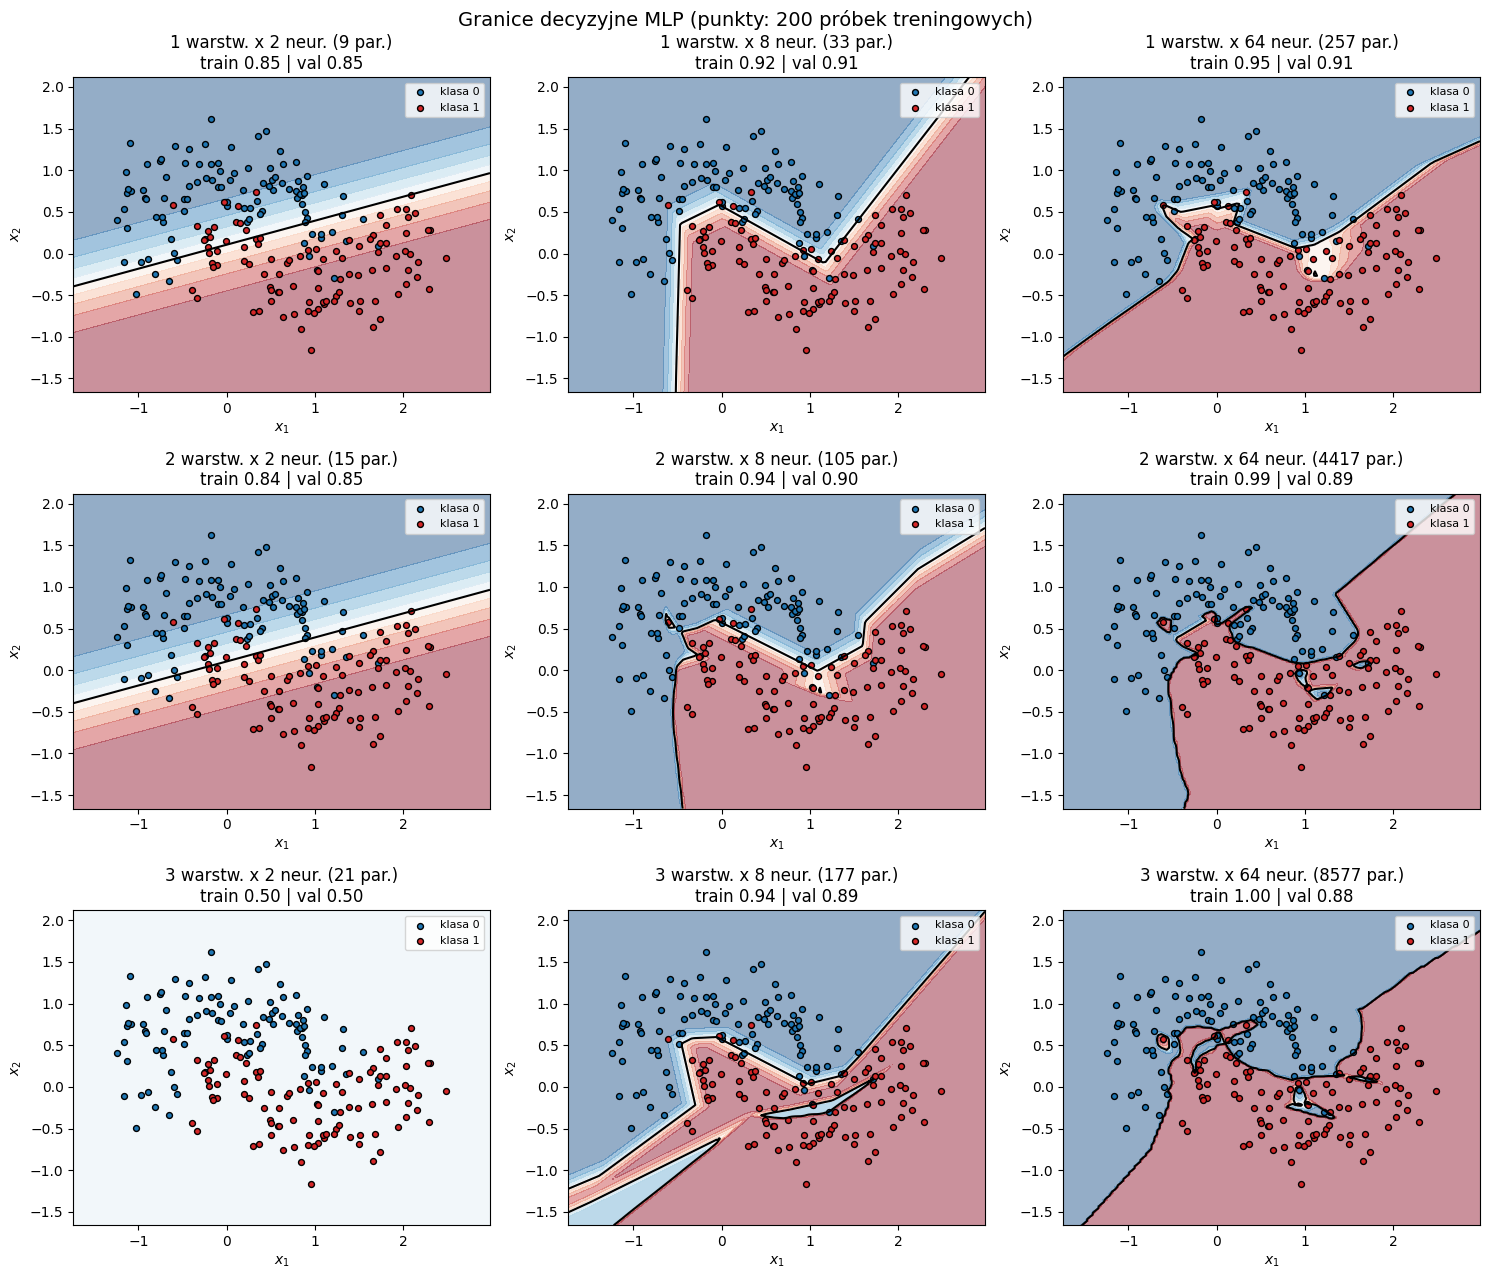

najlepsza architektura wg walidacji (warstwy, neurony): (1, 8) val acc = 0.908


In [104]:
if wyniki_siatka:
    fig, axes = plt.subplots(3, 3, figsize=(15, 13))
    for i, n_warstw in enumerate([1, 2, 3]):
        for j, n_neuronow in enumerate([2, 8, 64]):
            m, acc_tr, acc_va = wyniki_siatka[(n_warstw, n_neuronow)]
            n_par = sum(p.numel() for p in m.parameters())
            def pred(P, m=m):
                with torch.no_grad():
                    return torch.sigmoid(m(torch.tensor(P, device=DEVICE))).cpu().numpy()
            rysuj_granice(pred, X_s_tr, y_s_tr, ax=axes[i, j], rozdz=150,
                          tytul=f"{n_warstw} warstw. x {n_neuronow} neur. ({n_par} par.)\ntrain {acc_tr:.2f} | val {acc_va:.2f}")
    plt.suptitle("Granice decyzyjne MLP (punkty: 200 próbek treningowych)", fontsize=14)
    plt.tight_layout(); plt.show()

    najlepszy = max(wyniki_siatka, key=lambda k: wyniki_siatka[k][2])
    print("najlepsza architektura wg walidacji (warstwy, neurony):", najlepszy,
          "val acc =", round(wyniki_siatka[najlepszy][2], 3))

## Pytania kontrolne
1. Zapisz regułę uczenia perceptronu. Czym różni się od spadku gradientu? Kiedy perceptron gwarantuje zbieżność?
2. Dlaczego pojedynczy perceptron nie rozwiąże problemu XOR, a MLP z jedną warstwą ukrytą tak?
3. Dlaczego sieć bez nieliniowych funkcji aktywacji (dowolnie głęboka) jest równoważna modelowi liniowemu?
4. Wyjaśnij zjawisko znikającego gradientu. Dlaczego sigmoid jest na nie podatny bardziej niż ReLU?
5. Ile parametrów ma MLP o architekturze 10 -> 32 -> 16 -> 3? Pokaż obliczenia.
6. Dlaczego dla sigmoidu z BCE gradient po pobudzeniu wyjścia upraszcza się do $\hat y - y$? Jaka jest korzyść z używania `BCEWithLogitsLoss` (lub `from_logits=True`)?
7. Czym różni się Sequential API od Functional API w Keras? Podaj przykład architektury, której nie zbudujesz w Sequential.
8. Wymień kroki jednej iteracji pętli treningowej PyTorch. Co robią `model.train()`, `model.eval()` i `torch.no_grad()`?

### Odpowiedzi na pytania kontrolne

**1. Reguła perceptronu, różnica względem GD i warunek zbieżności.** Dla etykiet $y\in\{-1,+1\}$ i błędnie sklasyfikowanej próbki $(x,y)$ perceptron aktualizuje $w\leftarrow w+\eta yx$ i $b\leftarrow b+\eta y$. Jeśli klasyfikacja jest poprawna, nie zmienia wag. Reguła nie jest takim samym minimalizowaniem gładkiej funkcji straty jak klasyczny GD z gradientem MSE; wykonuje korektę wynikającą z błędu klasyfikacji (można ją też interpretować jako aktualizację na stracie perceptronowej). Twierdzenie o zbieżności gwarantuje skończoną liczbę pomyłek dla skończonego, **liniowo separowalnego** zbioru danych przy odpowiednich warunkach; nie daje takiej gwarancji dla XOR.

**2. Perceptron i XOR.** Jedna liniowa granica decyzyjna nie rozdzieli XOR, bo dodatnie i ujemne punkty leżą naprzemiennie. MLP z warstwą ukrytą i **nieliniową aktywacją** może połączyć kilka granic liniowych, tworząc nieliniową regułę XOR.

**3. Brak aktywacji w głębokiej sieci.** Złożenie przekształceń afinicznych wciąż jest przekształceniem afinicznym: $W_2(W_1x+b_1)+b_2=(W_2W_1)x+(W_2b_1+b_2)$. Kolejne warstwy bez nieliniowości nie zwiększają możliwości reprezentowania nieliniowych zależności.

**4. Znikający gradient.** Backprop mnoży wiele lokalnych pochodnych. Jeśli ich wartości bezwzględne są małe, gradient we wcześniejszych warstwach zanika. Sigmoid nasyca się w pobliżu 0 i 1, a jej pochodna jest nie większa niż $0{,}25$; ReLU ma pochodną $1$ dla dodatniego wejścia, więc w tym zakresie nie zmniejsza gradientu. ReLU może jednak mieć **martwe neurony** dla trwale ujemnych wejść (pochodna 0).

**5. Liczba parametrów `10 -> 32 -> 16 -> 3`.** W każdej warstwie: liczba wag = wejścia $\times$ wyjścia, a biasów = liczba wyjść. Warstwy mają odpowiednio $(10\cdot32+32)=352$, $(32\cdot16+16)=528$ i $(16\cdot3+3)=51$ parametrów. **Łącznie 931 parametrów.**

**6. Sigmoid + BCE oraz logits.** Dla logitu $z$, $p=\sigma(z)$ i binarnej entropii krzyżowej $L=-y\log p-(1-y)\log(1-p)$, reguła łańcuchowa daje $\partial L/\partial z = p-y$ (czynniki związane z pochodną sigmoidy upraszczają się). `BCEWithLogitsLoss` łączy operacje BCE i sigmoidę w sposób **stabilniejszy numerycznie**, zwłaszcza przy bardzo dużych logitach. Podajemy do niej **surowe logity**, bez wcześniejszej sigmoidy.

**7. Sequential i Functional API.** `Sequential` opisuje pojedynczy łańcuch warstw, w którym każde wyjście trafia do następnej warstwy. Functional API buduje graf z rozgałęzieniami i łączeniem ścieżek; wykorzystamy je np. do **sieci residualnej** z połączeniem `Add([x, F(x)])` albo modelu z dwoma wejściami.

**8. Iteracja treningowa i tryby PyTorch.** Typowy krok: `model.train()` (ustaw tryb treningowy), `optimizer.zero_grad()`, forward (`pred = model(x)`), policzenie straty, `loss.backward()` oraz `optimizer.step()`. `model.train()` aktywuje zachowanie treningowe np. Dropout/BatchNorm, `model.eval()` przełącza je na zachowanie ewaluacyjne, a `torch.no_grad()` wyłącza zapisywanie grafu gradientów przy predykcji i oszczędza zasoby. Samo `eval()` **nie wyłącza** obliczania gradientów.


## Podsumowanie - co warto zapamiętać
- **Perceptron** = liniowa granica + funkcja progowa; reguła uczenia działa tylko dla danych liniowo separowalnych; **XOR** jest dla niego nierozwiązywalny.
- **Nieliniowe aktywacje** są niezbędne - bez nich głęboka sieć jest liniowa. W warstwach ukrytych domyślnie **ReLU** (lub GELU), na wyjściu: sigmoid (binarna), softmax (wieloklasowa), brak (regresja).
- **Znikający gradient**: iloczyn wielu małych pochodnych (sigmoid ≤ 0.25) - pierwsze warstwy się nie uczą. Pomaga ReLU + inicjalizacja He (dalej: BatchNorm, połączenia residualne).
- **Backpropagation** = reguła łańcuchowa od straty do wejść; dla warstwy gęstej $\partial L/\partial W = A_{wej}^\top\,\delta$. Sigmoid + BCE daje $\delta = \hat y - y$. Ręczny backprop weryfikujemy **gradient checkiem**.
- **Liczba parametrów** warstwy gęstej: $(n_{in} + 1)\cdot n_{out}$.
- **Keras**: `Sequential` (stos) lub **Functional API** (dowolny graf) -> `compile` -> `fit` -> `evaluate`/`predict`.
- **PyTorch**: `nn.Module` + `DataLoader` + własna pętla (`zero_grad`, forward, strata, `backward`, `step`); do BCE podawaj **logity** (`BCEWithLogitsLoss`).
- **Pojemność** (warstwy x neurony) steruje złożonością granicy decyzyjnej; za mała - underfitting, za duża przy małej liczbie danych - overfitting. Wybór na **walidacji**.

## Do sprawozdania końcowego
Sprawozdanie końcowe obejmuje wyniki z L3-L7 i mini-projekt, więc z L2 **nic nie jest obowiązkowe**. Warto jednak zachować do części metodycznej mini-projektu:
- **ręczne obliczenie liczby parametrów** swojej architektury (jak w Zadaniu 4.1) i porównanie z `summary()` - będzie wymagane przy opisie modelu w mini-projekcie,
- siatkę granic decyzyjnych z Zadania 6.1 jako ilustrację wpływu pojemności (uzasadnienie wyboru rozmiaru sieci),
- jeśli w mini-projekcie użyjesz PyTorch - własną, przetestowaną funkcję `trenuj_epoke`/`ewaluuj` z Zadania 5.1.

## Zadanie dodatkowe (dla chętnych) - Uniwersalny MLP w NumPy dla klasyfikacji wieloklasowej (spirala)
Uogólnij ręczny backprop na **dowolną liczbę warstw** i **wiele klas**. Dane: trzy przeplatające się spirale (klasyczny przykład z kursu Stanford CS231n) - generowane lokalnie w NumPy.

Zaimplementuj klasę `MLPNumpy(rozmiary)`:
- inicjalizacja He: $W_l \sim \mathcal N(0, 2/n_{in})$, biasy zerowe,
- `forward(X)` - ReLU w warstwach ukrytych, **softmax** na wyjściu (stabilny!), zapamiętanie aktywacji,
- `strata(P, y)` - entropia krzyżowa wieloklasowa $L = -\frac1n\sum_i\log p_{i, y_i}$,
- `backward(y)` - dla softmax + CE: $\delta_L = \frac1n(P - Y_{onehot})$, dalej jak w sekcji 3, z pochodną ReLU $\mathbb 1[z > 0]$,
- `krok(lr)` - spadek gradientu.

Wytrenuj sieć `[2, 64, 64, 3]` (full-batch, lr = 0.5). **Cel:** dokładność treningowa > 95% i granica decyzyjna podążająca za spiralami. Porównaj z tym samym modelem w PyTorch (1-2 linijki zmian w `MLP`!) lub Keras.

spirala: dokładność treningowa = 0.993, strata = 0.0169


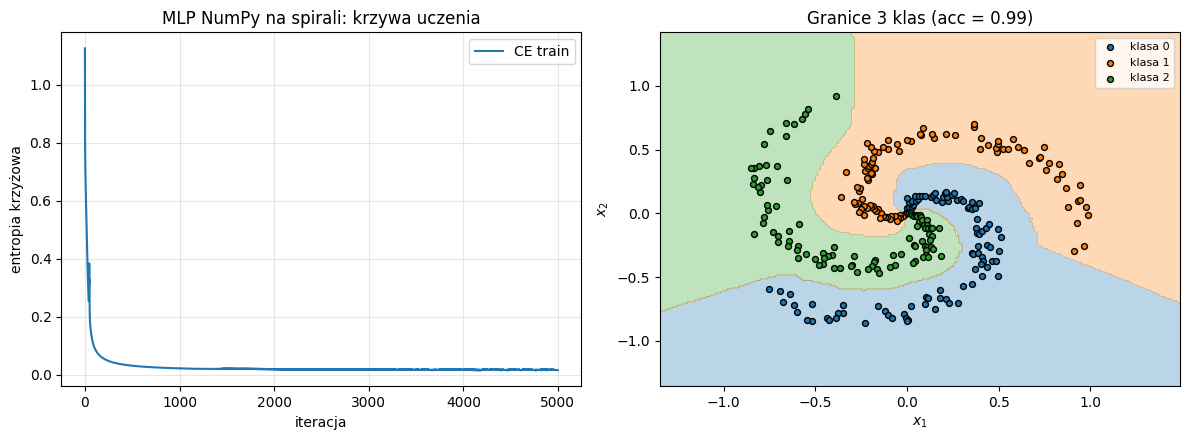

In [105]:
def spirala(n_na_klase=100, k=3, szum=0.2, seed=0):
    rng = np.random.default_rng(seed)
    X, y = [], []
    for j in range(k):
        r = np.linspace(0.0, 1.0, n_na_klase)                                   # promień
        t = np.linspace(j * 4, (j + 1) * 4, n_na_klase) + rng.normal(0, szum, n_na_klase)  # kąt
        X.append(np.c_[r * np.sin(t), r * np.cos(t)]); y.append(np.full(n_na_klase, j))
    return np.vstack(X), np.concatenate(y)

X_sp, y_sp = spirala()
ITER_SP = 300 if SZYBKI_TRYB else 5000


class MLPNumpy:
    def __init__(self, rozmiary, seed=0):
        rng = np.random.default_rng(seed)
        self.W = [rng.normal(0, np.sqrt(2.0 / a), (a, b)) for a, b in zip(rozmiary[:-1], rozmiary[1:])]
        self.b = [np.zeros(b) for b in rozmiary[1:]]

    def forward(self, X):
        self.A = [np.asarray(X)]
        self.Z = []
        for W, b in zip(self.W[:-1], self.b[:-1]):
            z = self.A[-1] @ W + b
            self.Z.append(z)
            self.A.append(np.maximum(0, z))
        z = self.A[-1] @ self.W[-1] + self.b[-1]
        self.Z.append(z)
        e = np.exp(z - z.max(axis=1, keepdims=True))
        P = e / e.sum(axis=1, keepdims=True)
        self.A.append(P)
        return P

    def strata(self, P, y):
        return -np.log(np.clip(P[np.arange(len(y)), y], 1e-12, 1)).mean()

    def backward(self, y):
        n = len(y)
        onehot = np.eye(self.A[-1].shape[1])[y]
        delta = (self.A[-1] - onehot) / n
        self.dW = [np.zeros_like(W) for W in self.W]
        self.db = [np.zeros_like(b) for b in self.b]
        for layer in range(len(self.W) - 1, -1, -1):
            self.dW[layer] = self.A[layer].T @ delta
            self.db[layer] = delta.sum(axis=0)
            if layer > 0:
                delta = (delta @ self.W[layer].T) * (self.Z[layer - 1] > 0)

    def krok(self, lr):
        for l in range(len(self.W)):
            self.W[l] -= lr * self.dW[l]
            self.b[l] -= lr * self.db[l]


mlp_np = MLPNumpy([2, 64, 64, 3])
hist_sp = []
for it in range(ITER_SP):
    P = mlp_np.forward(X_sp)
    hist_sp.append(mlp_np.strata(P, y_sp))
    mlp_np.backward(y_sp)
    mlp_np.krok(lr=0.5)
acc_sp = np.mean(mlp_np.forward(X_sp).argmax(axis=1) == y_sp)
print(f"spirala: dokładność treningowa = {acc_sp:.3f}, strata = {hist_sp[-1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(hist_sp, label="CE train"); ax[0].set_title("MLP NumPy na spirali: krzywa uczenia")
ax[0].set_xlabel("iteracja"); ax[0].set_ylabel("entropia krzyżowa"); ax[0].legend(); ax[0].grid(alpha=0.3)
rysuj_granice(lambda Pn: mlp_np.forward(Pn).argmax(axis=1), X_sp, y_sp, ax=ax[1], wieloklasowa=True,
              tytul=f"Granice 3 klas (acc = {acc_sp:.2f})")
plt.tight_layout(); plt.show()